# Experiment 3: Fuzzy Set Operations (Union, Intersection, Complement)

**Aim:** To perform basic fuzzy set operations such as Union, Intersection, and Complement using Python.

## Theory
For fuzzy sets A and B:
* **Union**: μ_(A∪B)(x) = max(μ_A(x), μ_B(x))
* **Intersection**: μ_(A∩B)(x) = min(μ_A(x), μ_B(x))
* **Complement**: μ_A'(x) = 1 − μ_A(x)

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
%matplotlib inline

### Step 2: Discrete fuzzy sets

In [2]:
X = ['a', 'b', 'c', 'd', 'e']
A = np.array([0.2, 0.5, 0.8, 1.0, 0.4])
B = np.array([0.6, 0.3, 0.7, 0.2, 0.9])

union        = np.maximum(A, B)
intersection = np.minimum(A, B)
comp_A       = 1 - A
comp_B       = 1 - B

print(f"{'x':>3} {'A':>5} {'B':>5} {'A U B':>7} {'A n B':>7} {'A c':>6} {'B c':>6}")
for i, e in enumerate(X):
    print(f"{e:>3} {A[i]:>5} {B[i]:>5} {union[i]:>7} {intersection[i]:>7} {comp_A[i]:>6.1f} {comp_B[i]:>6.1f}")

  x     A     B   A U B   A n B    A c    B c
  a   0.2   0.6     0.6     0.2    0.8    0.4
  b   0.5   0.3     0.5     0.3    0.5    0.7
  c   0.8   0.7     0.8     0.7    0.2    0.3
  d   1.0   0.2     1.0     0.2    0.0    0.8
  e   0.4   0.9     0.9     0.4    0.6    0.1


### Step 3: Plot the discrete operations

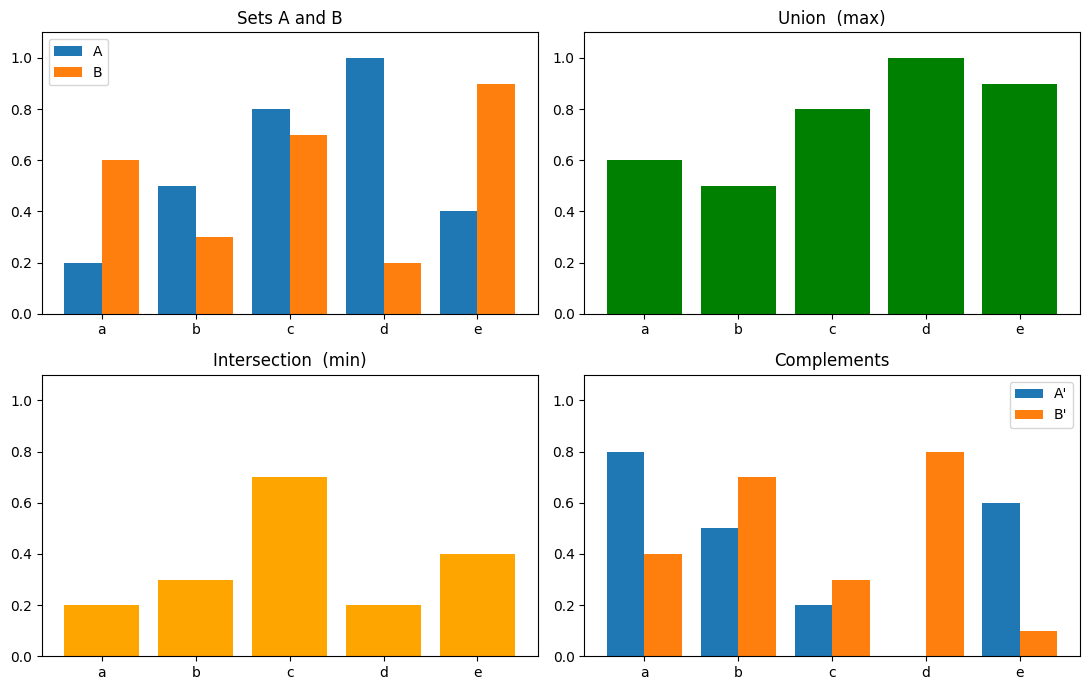

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
idx = np.arange(len(X))
ax[0,0].bar(idx-0.2, A, 0.4, label='A'); ax[0,0].bar(idx+0.2, B, 0.4, label='B'); ax[0,0].set_title('Sets A and B'); ax[0,0].legend()
ax[0,1].bar(idx, union, color='green');        ax[0,1].set_title('Union  (max)')
ax[1,0].bar(idx, intersection, color='orange'); ax[1,0].set_title('Intersection  (min)')
ax[1,1].bar(idx-0.2, comp_A, 0.4, label="A'"); ax[1,1].bar(idx+0.2, comp_B, 0.4, label="B'"); ax[1,1].set_title('Complements'); ax[1,1].legend()
for a in ax.flat:
    a.set_xticks(idx); a.set_xticklabels(X); a.set_ylim(0, 1.1)
plt.tight_layout(); plt.show()

### Step 4: Operations on continuous fuzzy sets using scikit-fuzzy

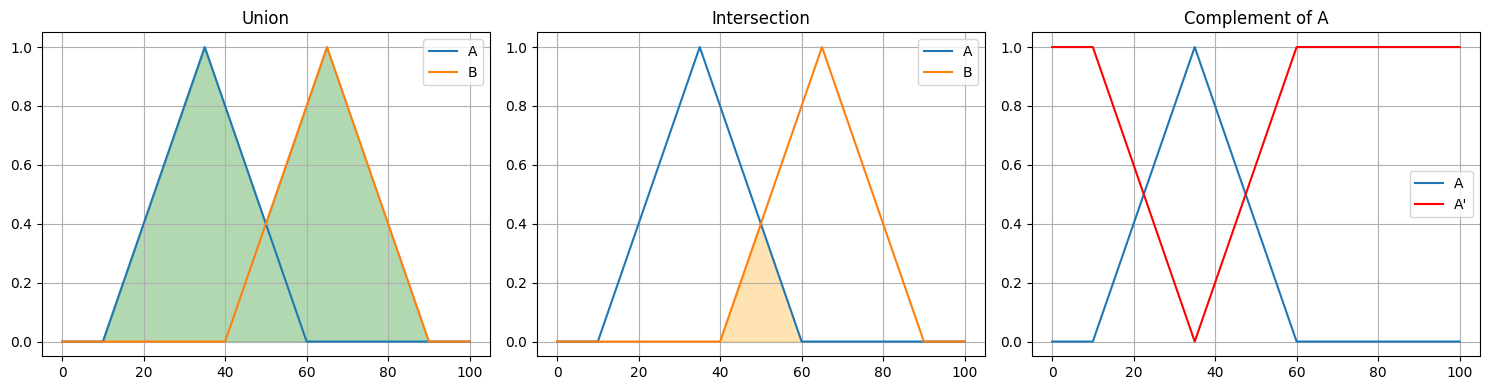

In [4]:
x = np.arange(0, 101, 1)
A_c = fuzz.trimf(x, [10, 35, 60])
B_c = fuzz.trimf(x, [40, 65, 90])

union_c = fuzz.fuzzy_or(x, A_c, x, B_c)[1]
inter_c = fuzz.fuzzy_and(x, A_c, x, B_c)[1]
comp_c  = fuzz.fuzzy_not(A_c)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(x, A_c, label='A'); ax[0].plot(x, B_c, label='B'); ax[0].fill_between(x, union_c, alpha=0.3, color='g'); ax[0].set_title('Union')
ax[1].plot(x, A_c, label='A'); ax[1].plot(x, B_c, label='B'); ax[1].fill_between(x, inter_c, alpha=0.3, color='orange'); ax[1].set_title('Intersection')
ax[2].plot(x, A_c, label='A'); ax[2].plot(x, comp_c, 'r', label="A'"); ax[2].set_title('Complement of A')
for a in ax: a.legend(); a.grid(True)
plt.tight_layout(); plt.show()

### Step 5: Verify De Morgan's laws
(A ∪ B)' = A' ∩ B'   and   (A ∩ B)' = A' ∪ B'

In [5]:
print("De Morgan 1:", np.allclose(1 - union, np.minimum(1 - A, 1 - B)))
print("De Morgan 2:", np.allclose(1 - intersection, np.maximum(1 - A, 1 - B)))
print("A U A' (not equal to universe in fuzzy logic):", np.maximum(A, 1 - A))
print("A n A' (not empty in fuzzy logic)            :", np.minimum(A, 1 - A))

De Morgan 1: True
De Morgan 2: True
A U A' (not equal to universe in fuzzy logic): [0.8 0.5 0.8 1.  0.6]
A n A' (not empty in fuzzy logic)            : [0.2 0.5 0.2 0.  0.4]


## Conclusion
Union (max), intersection (min) and complement (1 - μ) were implemented and visualised for discrete and continuous fuzzy sets. De Morgan's laws hold, while the laws of excluded middle and non-contradiction do not hold in fuzzy logic.